# Out-of-Distribution (OOD) Detection: Methods and Evaluation

**Module 02 · Failures and Robustness** · Notebook 3 of 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/02_Failures_and_Robustness/03_out_of_distribution_detection.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~80 min | [02 · Corner cases](02_corner_cases.ipynb); basic PyTorch (training loop, softmax) | ISO 21448:2022, ISO/PAS 8800:2024 (context) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook, you will be able to:

1. Explain the OOD problem, and distinguish covariate from semantic shift and near- from far-OOD
2. Implement five post-hoc OOD scores: maximum softmax probability (MSP), ODIN, energy, class-conditional Mahalanobis and k-nearest-neighbour (k-NN) distance
3. Evaluate detectors correctly with AUROC and FPR at 95% TPR, stating the convention used
4. Select hyperparameters and thresholds without touching the test set, and report the realised operating point
5. Interpret the limits of OOD detection as a safety measure

## Setup and imports

Everything runs **offline on a CPU in well under two minutes**: we use scikit-learn's built-in handwritten-digit images instead of downloading a dataset.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # tiny model: one thread is fastest and avoids CPU oversubscription
device = 'cpu'  # the model is tiny; a GPU brings no benefit

OKABE = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
T0 = time.time()
print(f"PyTorch {torch.__version__} | NumPy {np.__version__}")

PyTorch 2.15.0+cpu | NumPy 2.5.4


---

## The out-of-distribution problem

**In-distribution (ID):** data drawn from the same distribution as the training data.
**Out-of-distribution (OOD):** data from a different distribution.

### Examples in automated driving

**In-distribution:** cars, trucks, pedestrians, cyclists; clear weather; paved roads; standard signs and markings.

**Out-of-distribution:**
- Unusual objects: a sofa on the motorway, escaped animals
- Extreme weather: sandstorm, heavy snow, flooding
- Novel situations: an overturned truck, downed power lines
- Sensor degradation: dirty camera, misaligned LiDAR

### Why OOD detection matters

Neural networks are frequently **overconfident** on inputs unlike their training data: a classifier must output one of its known classes, and the softmax can be close to 1 even for nonsense inputs. **High confidence is not correctness.** An OOD detector adds a score that indicates "this input is unlike what the model was trained on", so that the system can react (log, degrade, hand over, slow down).

### Glossary (shared with Module 04)

| Term | Meaning | Driving example |
|---|---|---|
| **Covariate shift** | Input appearance changes, label set unchanged: $p(x)$ shifts, $p(y\mid x)$ intended unchanged | Same pedestrians, but at night, in fog or with a dirty lens |
| **Semantic shift** | New classes not in the label set | An e-scooter or a moose for a detector trained without them |
| **Near-OOD** | Semantically close to ID data; hard to detect | A new vehicle type that resembles known ones |
| **Far-OOD** | Very different from ID data; easier | Sensor noise, a blocked camera |
| **Post-hoc detector** | Score computed from a trained model without retraining | MSP, ODIN, energy, Mahalanobis, k-NN |

Covariate shift is not always "OOD" in the sense of *unknown*: a model may still be correct on mildly shifted inputs. Whether to flag them is a design decision that should follow the safety requirement, not the detector.

---

## Experimental setup (offline and reproducible)

The classic image benchmark is **CIFAR-10 (ID) vs SVHN (OOD)**; modern benchmarks such as OpenOOD v1.5 (Zhang et al., 2023) compare dozens of detectors, and driving-specific benchmarks include SegmentMeIfYouCan (Chan et al., 2021) for anomaly segmentation and CIFAR-10-C-style corruptions for covariate shift (Hendrycks & Dietterich, 2019). Downloading such data is slow and fragile in teaching environments, so we reproduce the **same methodology** on a small built-in dataset:

- **Data:** scikit-learn `load_digits` (1,797 grey-scale images, 8×8 pixels, values scaled to [0, 1])
- **ID task:** classify digits **0–4**
- **Splits of the ID data (stratified):** 60% **train** (model and detector statistics), 20% **validation** (hyperparameters and thresholds), 20% **test** (reported once)
- **OOD test sets:**
  1. **Held-out digits 5–9** — *semantic shift, near-OOD* (same sensor, new classes)
  2. **ID test digits + heavy Gaussian noise** (σ = 0.35) — *covariate shift* (sensor degradation)
  3. **Inverted ID test digits** (1 − x) — *covariate shift* (e.g. a polarity/exposure change)
  4. **Uniform noise images** — *far-OOD* (a failed sensor)

**Rule:** nothing about the OOD test sets is used to train the model, fit statistics or choose thresholds.

ID  train / val / test : 540 / 180 / 181 images (classes [0, 1, 2, 3, 4])
OOD Held-out digits 5-9 (semantic, near)  : 896 images
OOD ID + heavy noise (covariate)          : 181 images
OOD Inverted ID (covariate)               : 181 images
OOD Uniform noise (far)                   : 181 images


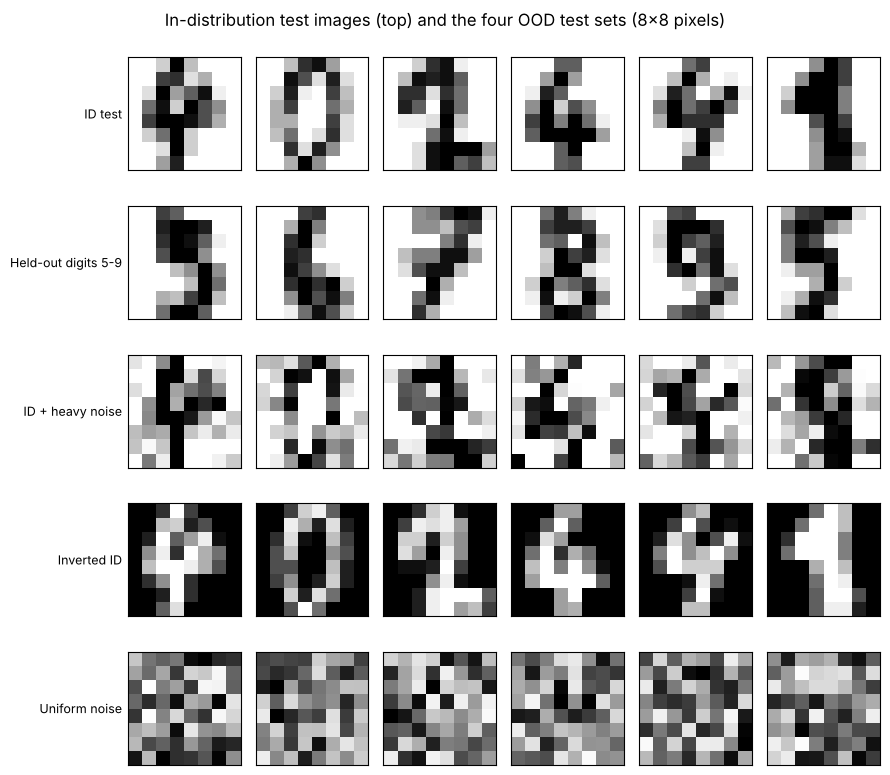

--- Text summary --- one row per data set: ID test digits, held-out digits, noisy digits, inverted digits, uniform noise.


In [2]:
digits = load_digits()
X_all = (digits.images / 16.0).astype(np.float32)   # (N, 8, 8), values in [0, 1]
y_all = digits.target
ID_CLASSES = [0, 1, 2, 3, 4]
is_id = np.isin(y_all, ID_CLASSES)

X_id, y_id = X_all[is_id], y_all[is_id]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X_id, y_id, test_size=0.4, stratify=y_id, random_state=SEED)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

ood_sets = {
    'Held-out digits 5-9 (semantic, near)': X_all[~is_id],
    'ID + heavy noise (covariate)': np.clip(X_te + rng.normal(0, 0.35, X_te.shape), 0, 1).astype(np.float32),
    'Inverted ID (covariate)': (1.0 - X_te).astype(np.float32),
    'Uniform noise (far)': rng.uniform(0, 1, (len(X_te), 8, 8)).astype(np.float32),
}
print(f"ID  train / val / test : {len(X_tr)} / {len(X_val)} / {len(X_te)} images (classes {ID_CLASSES})")
for name, X in ood_sets.items():
    print(f"OOD {name:38s}: {len(X)} images")

fig, axes = plt.subplots(len(ood_sets) + 1, 6, figsize=(9, 8))
rows = [('ID test', X_te)] + list(ood_sets.items())
for r, (name, X) in enumerate(rows):
    for c in range(6):
        axes[r, c].imshow(X[c], cmap='gray_r', vmin=0, vmax=1)
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([]); axes[r, c].grid(False)
    axes[r, 0].set_ylabel(name.split(' (')[0], rotation=0, ha='right', va='center', fontsize=9)
fig.suptitle('In-distribution test images (top) and the four OOD test sets (8x8 pixels)')
plt.tight_layout()
plt.show()
print("--- Text summary --- one row per data set: ID test digits, held-out digits, noisy digits, "
      "inverted digits, uniform noise.")

---

## A small classifier (no BatchNorm)

A two-layer convolutional network with a 64-dimensional penultimate layer. We deliberately avoid BatchNorm: its train/eval behaviour is a common source of bugs in uncertainty code (in `train()` mode it uses batch statistics and silently **updates its running statistics with whatever data passes through**, including OOD data). The model is always used in `eval()` mode after training.

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.fc1 = nn.Linear(32 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, n_classes)

    def features(self, x):                 # penultimate-layer features (64-d)
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return F.relu(self.fc1(x.flatten(1)))

    def forward(self, x):
        return self.fc2(self.features(x))

to_t = lambda X: torch.from_numpy(np.asarray(X, dtype=np.float32)).unsqueeze(1)
xtr, ytr_t = to_t(X_tr), torch.from_numpy(y_tr)

model = SmallCNN(len(ID_CLASSES))
opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
t = time.time()
for epoch in range(50):
    model.train()
    perm = torch.randperm(len(xtr))
    for i in range(0, len(xtr), 128):
        b = perm[i:i + 128]
        opt.zero_grad()
        F.cross_entropy(model(xtr[b]), ytr_t[b]).backward()
        opt.step()
model.eval()

@torch.no_grad()
def logits_and_features(X):
    f = model.features(to_t(X))
    return model.fc2(f).numpy(), f.numpy()

acc = lambda X, y: float((logits_and_features(X)[0].argmax(1) == y).mean())
print(f"Training time: {time.time() - t:.1f} s")
print(f"Accuracy  train {acc(X_tr, y_tr):.3f} | val {acc(X_val, y_val):.3f} | test {acc(X_te, y_te):.3f}")

Training time: 2.4 s
Accuracy  train 1.000 | val 0.983 | test 0.994


---

## Method 1: maximum softmax probability (MSP, baseline)

Hendrycks & Gimpel (2017): use the classifier's confidence as the ID score,
$$S_{\mathrm{MSP}}(x) = \max_c \, \mathrm{softmax}(f(x))_c .$$
High → in-distribution; low → OOD. Simple and surprisingly strong, but softmax confidence is not designed to be low on unfamiliar inputs.

**Convention in this notebook:** every score is oriented so that **higher = more in-distribution**.

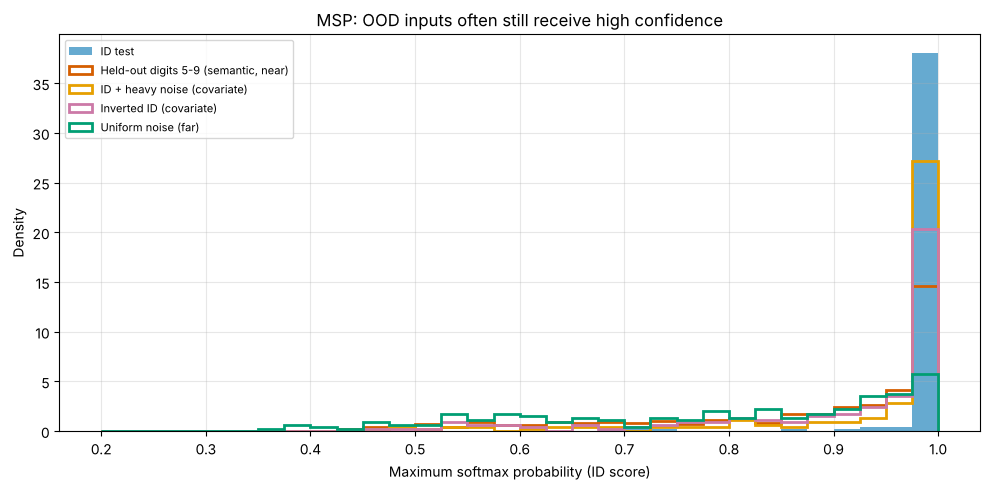

--- Text summary (share of images with MSP > 0.9) ---
  ID test: 97.8%
  Held-out digits 5-9 (semantic, near)  : 59.5%
  ID + heavy noise (covariate)          : 80.7%
  Inverted ID (covariate)               : 70.2%
  Uniform noise (far)                   : 38.1%


In [4]:
def softmax_np(z, T=1.0):
    z = z / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def score_msp(X):
    return softmax_np(logits_and_features(X)[0]).max(1)

msp_id = score_msp(X_te)
msp_ood = {k: score_msp(X) for k, X in ood_sets.items()}

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(0.2, 1.0, 33)
ax.hist(msp_id, bins=bins, density=True, alpha=0.6, color=OKABE[4], label='ID test')
for (k, s), col in zip(msp_ood.items(), [OKABE[5], OKABE[0], OKABE[6], OKABE[2]]):
    ax.hist(s, bins=bins, density=True, histtype='step', lw=2, color=col, label=k)
ax.set_xlabel('Maximum softmax probability (ID score)')
ax.set_ylabel('Density')
ax.set_title('MSP: OOD inputs often still receive high confidence')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

print("--- Text summary (share of images with MSP > 0.9) ---")
print(f"  ID test: {np.mean(msp_id > 0.9):.1%}")
for k, s in msp_ood.items():
    print(f"  {k:38s}: {np.mean(s > 0.9):.1%}")

---

## Method 2: ODIN — temperature scaling and input perturbation

Liang et al. (2018) improve MSP with two tricks:

1. **Temperature scaling** with a large $T$ (e.g. 1000): $S(x;T) = \max_c \mathrm{softmax}(f(x)/T)_c$
2. **Input perturbation** that increases the softmax score; the effect is larger for ID than for OOD inputs:
$$\tilde{x} = x - \varepsilon \, \mathrm{sign}\big(-\nabla_x \log S_{\hat{y}}(x;T)\big), \qquad S_{\mathrm{ODIN}}(x) = \max_c \mathrm{softmax}(f(\tilde{x})/T)_c$$

$\varepsilon$ is in input units (here pixel values in [0, 1]); $\tilde{x}$ is clipped to [0, 1].

**Hyperparameter selection without OOD data:** the original paper tuned $\varepsilon$ on OOD validation samples, which is unrealistic (the unknown is unknown). We follow Hsu et al. (2020) and choose $\varepsilon$ to **maximise the mean score on ID validation data only**.

In [5]:
def score_odin(X, T=1000.0, eps=0.0):
    x = to_t(X).requires_grad_(True)
    log_sm = F.log_softmax(model(x) / T, dim=1)
    loss = -log_sm.max(1).values.sum()          # -log S_yhat(x; T)
    grad, = torch.autograd.grad(loss, x)
    x_tilde = (x - eps * grad.sign()).clamp(0, 1).detach()
    with torch.no_grad():
        return F.softmax(model(x_tilde) / T, dim=1).max(1).values.numpy()

T_ODIN = 1000.0
eps_grid = [0.0, 0.0025, 0.005, 0.01, 0.02, 0.04, 0.08]
val_means = [score_odin(X_val, T_ODIN, e).mean() for e in eps_grid]
EPS_ODIN = eps_grid[int(np.argmax(val_means))]
for e, m in zip(eps_grid, val_means):
    print(f"  eps={e:<7} mean ID-validation score={m:.6f}" + ("  <- selected" if e == EPS_ODIN else ""))

odin_id = score_odin(X_te, T_ODIN, EPS_ODIN)
odin_ood = {k: score_odin(X, T_ODIN, EPS_ODIN) for k, X in ood_sets.items()}
print(f"\nODIN with T={T_ODIN:.0f}, eps={EPS_ODIN} (selected on ID validation data only)")
if EPS_ODIN == eps_grid[-1]:
    print("Note: the ID-only criterion selected the largest eps in the grid; it does not tell us how this")
    print("choice affects OOD inputs - compare ODIN with MSP in the results below.")

  eps=0.0     mean ID-validation score=0.202493
  eps=0.0025  mean ID-validation score=0.202510
  eps=0.005   mean ID-validation score=0.202526
  eps=0.01    mean ID-validation score=0.202558
  eps=0.02    mean ID-validation score=0.202622
  eps=0.04    mean ID-validation score=0.202745
  eps=0.08    mean ID-validation score=0.202967  <- selected



ODIN with T=1000, eps=0.08 (selected on ID validation data only)
Note: the ID-only criterion selected the largest eps in the grid; it does not tell us how this
choice affects OOD inputs - compare ODIN with MSP in the results below.


---

## Method 3: energy score

Liu et al. (2020) use the (negative) free energy of the logits:
$$E(x;T) = -T \log \sum_{c=1}^{C} e^{f_c(x)/T}, \qquad S_{\mathrm{energy}}(x) = -E(x;T) = T\,\mathrm{logsumexp}(f(x)/T).$$

ID inputs tend to have **lower energy** (larger logits), so $-E$ is used as the ID score. Unlike MSP, it is not squashed into [0, 1] and keeps information about the logit magnitude. We use $T = 1$.

In [6]:
def score_energy(X, T=1.0):
    z = logits_and_features(X)[0] / T
    m = z.max(1, keepdims=True)
    return (T * (m + np.log(np.exp(z - m).sum(1, keepdims=True)))).ravel()   # = -E(x;T)

energy_id = score_energy(X_te)
energy_ood = {k: score_energy(X) for k, X in ood_sets.items()}
print(f"Mean -E: ID test {energy_id.mean():.2f}; " +
      "; ".join(f"{k.split(' (')[0]} {v.mean():.2f}" for k, v in energy_ood.items()))

Mean -E: ID test 11.83; Held-out digits 5-9 5.72; ID + heavy noise 8.59; Inverted ID 9.53; Uniform noise 4.96


---

## Method 4: class-conditional Mahalanobis distance

Lee et al. (2018) model the penultimate features of each class $c$ as a Gaussian with class mean $\mu_c$ and a **shared (tied) covariance** $\Sigma$, both estimated on **training** data:
$$M(x) = \min_c \,(\phi(x)-\mu_c)^\top \Sigma^{-1} (\phi(x)-\mu_c), \qquad S_{\mathrm{Maha}}(x) = -M(x).$$

This is a simplified version: the original also uses input pre-processing and an ensemble over several layers. A single global Gaussian (one mean for all classes) is weaker, because the ID feature distribution is multi-modal.

In [7]:
_, feat_tr = logits_and_features(X_tr)
mus = np.stack([feat_tr[y_tr == c].mean(0) for c in ID_CLASSES])
centred = np.concatenate([feat_tr[y_tr == c] - mus[i] for i, c in enumerate(ID_CLASSES)])
Sigma = centred.T @ centred / len(centred)
Sigma += 1e-3 * np.trace(Sigma) / Sigma.shape[0] * np.eye(Sigma.shape[0])   # small ridge for invertibility
P = np.linalg.inv(Sigma)

def score_mahalanobis(X):
    f = logits_and_features(X)[1]
    d2 = np.stack([np.einsum('ij,jk,ik->i', f - mu, P, f - mu) for mu in mus], axis=1)
    return -d2.min(1)

maha_id = score_mahalanobis(X_te)
maha_ood = {k: score_mahalanobis(X) for k, X in ood_sets.items()}
print(f"Fitted {len(mus)} class means and one tied covariance on {len(feat_tr)} training feature vectors "
      f"(dimension {feat_tr.shape[1]}).")

Fitted 5 class means and one tied covariance on 540 training feature vectors (dimension 64).


---

## Method 5: k-nearest-neighbour distance

Sun et al. (2022) avoid any distributional assumption: normalise the penultimate features to unit length and use the distance to the **k-th nearest training feature** as the OOD score,
$$S_{k\mathrm{NN}}(x) = -\big\lVert z(x) - z_{(k)} \big\rVert_2, \qquad z = \phi/\lVert\phi\rVert_2 .$$

The memory bank is the training set. We use a fixed  = 10$ (Sun et al. use larger $ for larger memory banks); tuning $ properly would need OOD-like validation data, which we do not assume to have.

In [8]:
def _unit(f):
    return f / (np.linalg.norm(f, axis=1, keepdims=True) + 1e-12)

bank = _unit(feat_tr)

def score_knn(X, k=10):
    z = _unit(logits_and_features(X)[1])
    d = np.sqrt(np.clip(2 - 2 * z @ bank.T, 0, None))   # Euclidean distance between unit vectors
    return -np.sort(d, axis=1)[:, k - 1]

K_NN = 10
knn_id = score_knn(X_te, K_NN)
knn_ood = {k: score_knn(X, K_NN) for k, X in ood_sets.items()}
print(f"k-NN with k={K_NN}, memory bank = {len(bank)} normalised training features.")

k-NN with k=10, memory bank = 540 normalised training features.


---

## Evaluation: AUROC and FPR at 95% TPR

We treat **ID as the positive class** and use scores where higher = more ID (the convention of Liang et al., 2018 and Liu et al., 2020):

- **AUROC:** probability that a random ID image scores higher than a random OOD image. 1.0 = perfect separation, 0.5 = chance. AUROC is **threshold-free** — it describes the detector, not a deployed operating point.
- **FPR@95TPR (FPR95):** choose the threshold at which **95% of ID images are accepted**; FPR95 is the **fraction of OOD images that are also accepted** (missed). Lower is better.

> Targets such as "AUROC > 0.95" are **illustrative only**. Real requirements must be derived from vehicle-level acceptance criteria and allocated to the monitor — e.g. a required detection probability for relevant OOD inputs at the operating threshold, and a tolerable false-alarm rate per hour of driving (Module 04).

OOD set,"Held-out digits 5-9 (semantic, near)",ID + heavy noise (covariate),Inverted ID (covariate),Uniform noise (far)
Method,,,,
MSP,0.937,0.751,0.880,0.972
ODIN,0.932,0.733,0.783,0.963
Energy,0.954,0.759,0.725,0.985
Mahalanobis,0.936,0.922,1.000,1.000
k-NN,0.970,0.805,0.979,0.989


OOD set,"Held-out digits 5-9 (semantic, near)",ID + heavy noise (covariate),Inverted ID (covariate),Uniform noise (far)
Method,,,,
MSP,0.350,0.674,0.486,0.127
ODIN,0.369,0.680,0.867,0.204
Energy,0.292,0.669,0.967,0.088
Mahalanobis,0.288,0.381,0.000,0.000
k-NN,0.211,0.713,0.122,0.061


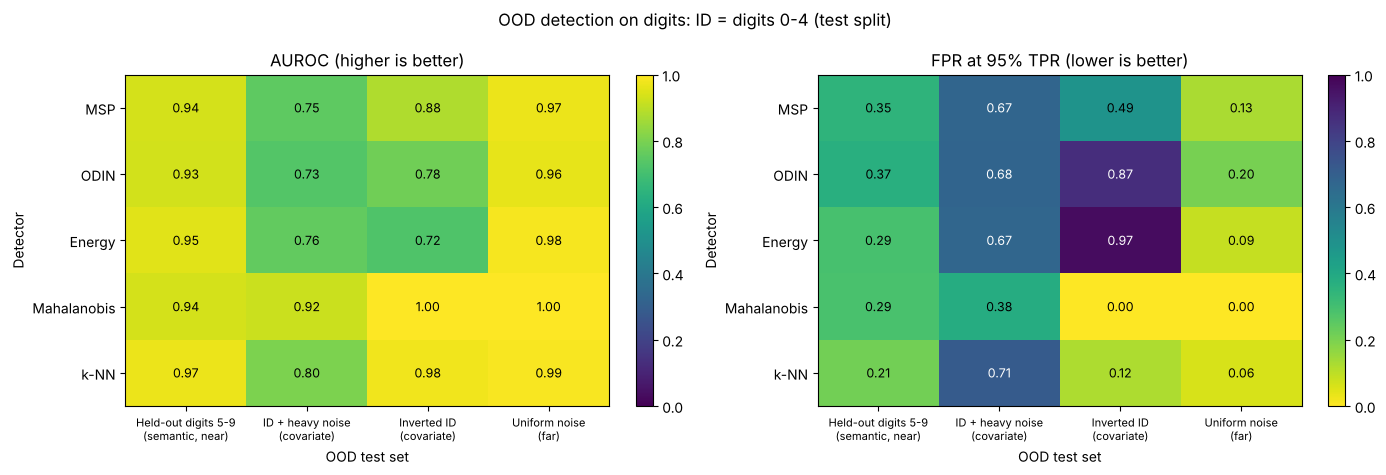

--- Results (derived) ---
  Held-out digits 5-9 (semantic, near)  : best AUROC k-NN (0.970), worst ODIN (0.932); best FPR95 k-NN (0.21)
  ID + heavy noise (covariate)          : best AUROC Mahalanobis (0.922), worst ODIN (0.733); best FPR95 Mahalanobis (0.38)
  Inverted ID (covariate)               : best AUROC Mahalanobis (1.000), worst Energy (0.725); best FPR95 Mahalanobis (0.00)
  Uniform noise (far)                   : best AUROC Mahalanobis (1.000), worst ODIN (0.963); best FPR95 Mahalanobis (0.00)
  Mean AUROC rank across OOD sets: Mahalanobis 1.8, k-NN 1.8, Energy 3.2, MSP 3.5, ODIN 4.8
  Hardest OOD set (lowest best-AUROC): ID + heavy noise (covariate)


In [9]:
def evaluate(id_scores, ood_scores, tpr_target=0.95):
    y = np.r_[np.ones(len(id_scores)), np.zeros(len(ood_scores))]
    s = np.r_[id_scores, ood_scores]
    auroc = roc_auc_score(y, s)
    fpr, tpr, _ = roc_curve(y, s)
    fpr95 = float(fpr[np.searchsorted(tpr, tpr_target, side='left')])   # first point with TPR >= 95%
    return auroc, fpr95, (fpr, tpr)

methods = {
    'MSP': (msp_id, msp_ood),
    'ODIN': (odin_id, odin_ood),
    'Energy': (energy_id, energy_ood),
    'Mahalanobis': (maha_id, maha_ood),
    'k-NN': (knn_id, knn_ood),
}
rows, rocs = [], {}
for m, (sid, sood) in methods.items():
    for k, so in sood.items():
        auroc, fpr95, curve = evaluate(sid, so)
        rows.append({'Method': m, 'OOD set': k, 'AUROC': auroc, 'FPR95': fpr95})
        rocs[(m, k)] = curve
results = pd.DataFrame(rows)
auroc_tab = results.pivot(index='Method', columns='OOD set', values='AUROC').loc[list(methods)]
fpr_tab = results.pivot(index='Method', columns='OOD set', values='FPR95').loc[list(methods)]
display(auroc_tab.round(3))
display(fpr_tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, tab, title, cmap in [(axes[0], auroc_tab, 'AUROC (higher is better)', 'viridis'),
                             (axes[1], fpr_tab, 'FPR at 95% TPR (lower is better)', 'viridis_r')]:
    im = ax.imshow(tab.values, cmap=cmap, vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(tab.shape[1]))
    ax.set_xticklabels([c.replace(' (', '\n(') for c in tab.columns], fontsize=8)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
    ax.grid(False)
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha='center', va='center', fontsize=9,
                    color='white' if (v < 0.5) == (cmap == 'viridis') else 'black')
    ax.set_title(title)
    ax.set_xlabel('OOD test set')
    ax.set_ylabel('Detector')
    plt.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle('OOD detection on digits: ID = digits 0-4 (test split)')
plt.tight_layout()
plt.show()

print("--- Results (derived) ---")
for k in auroc_tab.columns:
    best = auroc_tab[k].idxmax(); worst = auroc_tab[k].idxmin()
    print(f"  {k:38s}: best AUROC {best} ({auroc_tab.loc[best, k]:.3f}), "
          f"worst {worst} ({auroc_tab.loc[worst, k]:.3f}); best FPR95 {fpr_tab[k].idxmin()} ({fpr_tab[k].min():.2f})")
mean_rank = auroc_tab.rank(axis=0, ascending=False).mean(axis=1).sort_values()
print("  Mean AUROC rank across OOD sets: " + ", ".join(f"{m} {r:.1f}" for m, r in mean_rank.items()))
print(f"  Hardest OOD set (lowest best-AUROC): {auroc_tab.max(axis=0).idxmin()}")

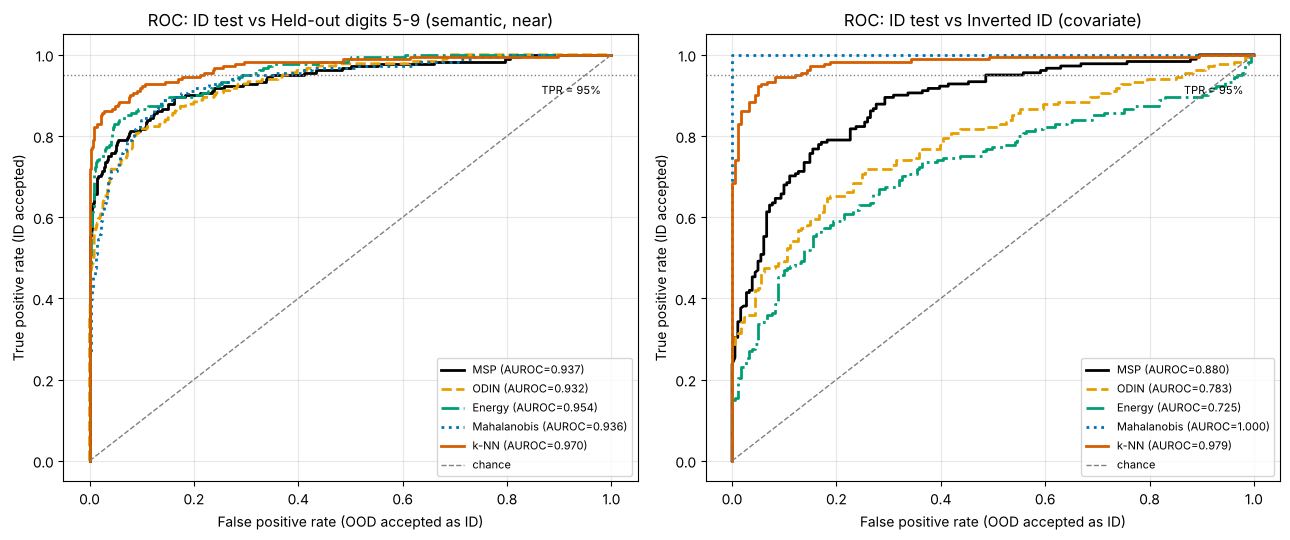

--- Text summary --- ROC curves for the near-OOD (held-out digits) and inverted-digit sets; values as in the tables above.


In [10]:
show_sets = [list(ood_sets)[0], list(ood_sets)[2]]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
cols = dict(zip(methods, [OKABE[7], OKABE[0], OKABE[2], OKABE[4], OKABE[5]]))
styles = dict(zip(methods, ['-', '--', '-.', ':', '-']))
for ax, k in zip(axes, show_sets):
    for m in methods:
        fpr, tpr = rocs[(m, k)]
        ax.plot(fpr, tpr, styles[m], color=cols[m], lw=2,
                label=f"{m} (AUROC={auroc_tab.loc[m, k]:.3f})")
    ax.plot([0, 1], [0, 1], color='grey', lw=1, ls='--', label='chance')
    ax.axhline(0.95, color='grey', lw=1, ls=':')
    ax.text(0.98, 0.93, 'TPR = 95%', ha='right', va='top', fontsize=8)
    ax.set_xlabel('False positive rate (OOD accepted as ID)')
    ax.set_ylabel('True positive rate (ID accepted)')
    ax.set_title(f'ROC: ID test vs {k}')
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()
print("--- Text summary --- ROC curves for the near-OOD (held-out digits) and inverted-digit sets; "
      "values as in the tables above.")

---

## From AUROC to an operating point (no test-set leakage)

A deployed monitor needs a **threshold**. We set it on **ID validation data** so that 95% of validation images are accepted, and only then measure on the test sets. The realised TPR on the ID test set will differ slightly from 95% — that is the honest number to report.

In [11]:
val_scores = {
    'MSP': score_msp(X_val), 'ODIN': score_odin(X_val, T_ODIN, EPS_ODIN), 'Energy': score_energy(X_val),
    'Mahalanobis': score_mahalanobis(X_val), 'k-NN': score_knn(X_val, K_NN),
}
op_rows = []
for m, (sid, sood) in methods.items():
    thr = np.quantile(val_scores[m], 0.05)          # accept 95% of ID validation images
    row = {'Method': m, 'Threshold': thr, 'ID test accepted (TPR)': np.mean(sid >= thr)}
    for k, so in sood.items():
        row[f"OOD flagged: {k.split(' (')[0]}"] = np.mean(so < thr)
    op_rows.append(row)
op = pd.DataFrame(op_rows).set_index('Method')
display(op.round(3))

print("--- Operating point (threshold from ID validation, 95% target) ---")
for m, r in op.iterrows():
    flagged = ', '.join(f"{c.split(': ')[1]} {v:.0%}" for c, v in r.items() if c.startswith('OOD'))
    print(f"  {m:12s}: ID test accepted {r['ID test accepted (TPR)']:.1%} | OOD flagged -> {flagged}")

,Threshold,ID test accepted (TPR),OOD flagged: Held-out digits 5-9,OOD flagged: ID + heavy noise,OOD flagged: Inverted ID,OOD flagged: Uniform noise
Method,,,,,,
MSP,0.986000,0.928,0.686,0.348,0.564,0.901
ODIN,0.202000,0.912,0.740,0.387,0.276,0.901
Energy,7.635000,0.895,0.843,0.436,0.166,0.972
Mahalanobis,-102.605003,0.956,0.614,0.558,1.000,1.000
k-NN,-0.225000,0.928,0.865,0.376,0.934,0.972


--- Operating point (threshold from ID validation, 95% target) ---
  MSP         : ID test accepted 92.8% | OOD flagged -> Held-out digits 5-9 69%, ID + heavy noise 35%, Inverted ID 56%, Uniform noise 90%
  ODIN        : ID test accepted 91.2% | OOD flagged -> Held-out digits 5-9 74%, ID + heavy noise 39%, Inverted ID 28%, Uniform noise 90%
  Energy      : ID test accepted 89.5% | OOD flagged -> Held-out digits 5-9 84%, ID + heavy noise 44%, Inverted ID 17%, Uniform noise 97%
  Mahalanobis : ID test accepted 95.6% | OOD flagged -> Held-out digits 5-9 61%, ID + heavy noise 56%, Inverted ID 100%, Uniform noise 100%
  k-NN        : ID test accepted 92.8% | OOD flagged -> Held-out digits 5-9 86%, ID + heavy noise 38%, Inverted ID 93%, Uniform noise 97%


### Does the OOD score also warn about *errors*?

For safety, the relevant question is often not "is this input novel?" but "**is the prediction likely to be wrong?**". Under covariate shift (noisy digits) the true labels are still known, so we can check whether the scores rank wrong predictions below correct ones.

In [12]:
X_shift = ood_sets['ID + heavy noise (covariate)']
pred_shift = logits_and_features(X_shift)[0].argmax(1)
wrong = pred_shift != y_te
print(f"Accuracy on ID test: {acc(X_te, y_te):.1%} | on noisy ID test: {1 - wrong.mean():.1%} "
      f"({int(wrong.sum())} of {len(wrong)} wrong)")
if 0 < wrong.sum() < len(wrong):
    for m, (_, sood) in methods.items():
        s = sood['ID + heavy noise (covariate)']
        print(f"  {m:12s}: AUROC for separating correct from wrong predictions = "
              f"{roc_auc_score(~wrong, s):.3f}")
print("Interpretation: a score can be good at spotting novelty yet weak at predicting errors, and vice versa;")
print("both properties must be evaluated for the intended safety use.")

Accuracy on ID test: 99.4% | on noisy ID test: 89.0% (20 of 181 wrong)
  MSP         : AUROC for separating correct from wrong predictions = 0.851
  ODIN        : AUROC for separating correct from wrong predictions = 0.776
  Energy      : AUROC for separating correct from wrong predictions = 0.825
  Mahalanobis : AUROC for separating correct from wrong predictions = 0.599
  k-NN        : AUROC for separating correct from wrong predictions = 0.834
Interpretation: a score can be good at spotting novelty yet weak at predicting errors, and vice versa;
both properties must be evaluated for the intended safety use.


### What the results show

Read the tables above rather than any general ranking:
- **No single detector wins everywhere.** Feature-space methods (Mahalanobis, k-NN) and logit-based methods (MSP, ODIN, energy) respond differently to different kinds of shift; logit-based scores can be weak on covariate shift (compare the inverted-digit column).
- **Published improvements do not automatically transfer.** ODIN and energy were shown to beat MSP on large CIFAR-scale models; on this small model and with ε chosen without OOD data, check the table before assuming they help.
- **Near-OOD (new digit classes) is usually harder than far-OOD (noise)** — check whether this holds in the table.
- **Covariate shift is ambiguous:** a noisy "3" is still a "3"; flagging it is right only if the model's accuracy actually degrades — see the error-detection check.
- Results on 8×8 digits **do not transfer** to driving perception; the methodology (splits, convention, operating point) does. Benchmark your own detector on ODD-relevant OOD data.

---

## Safety perspective

- **What OOD detection is — and is not.** OOD is defined relative to the **training data**, not to hazards. Many OOD inputs are harmless and many hazardous inputs are in-distribution. ISO 21448:2022 does not require an "OOD detector"; it expects functional insufficiencies and triggering conditions to be identified, evaluated and mitigated. A runtime OOD monitor is **one possible measure** against performance insufficiencies, and logged OOD events can feed the discovery of previously unknown hazardous scenarios (Area 3) during development and operation. ISO/PAS 8800:2024 discusses such monitoring for AI components.
- **Response:** if the monitor fires, the system may degrade, request a takeover (Level 3) or execute a **minimal risk manoeuvre** towards a **minimal risk condition** (Level 4) — designing that response is a system-level task.
- **Requirements and thresholds** must be derived from the safety goal: the required detection rate on relevant OOD inputs and a tolerable false-alarm rate (per hour, after temporal filtering).

Continue with:
- [04 · OOD monitoring as a SOTIF safety measure](../04_SOTIF_ISO21448/03_ood_monitoring_as_safety_measure.ipynb) — threshold selection from requirements, temporal filtering, fallback policy
- [06 · Uncertainty types](../06_AI_Safety_ISO_PAS_8800/02_uncertainty_types.ipynb), [06 · MC Dropout and deep ensembles](../06_AI_Safety_ISO_PAS_8800/03_mc_dropout_and_deep_ensembles.ipynb), [06 · Calibration](../06_AI_Safety_ISO_PAS_8800/04_calibration.ipynb)
- [07 · ODD and runtime monitoring](../07_Runtime_Assurance_and_Operations/01_odd_and_runtime_monitoring.ipynb)

---

## Exercise: design an OOD detector

**Task:** you are designing an OOD monitor for a driverless campus shuttle's pedestrian/cyclist classifier.

**In-distribution:** students walking, bicycles, campus buses; paved roads, crosswalks; clear weather, daylight; 15–25 km/h.

1. List OOD inputs you expect, and label each as covariate or semantic shift, near or far.
2. Which detector(s) would you choose, and why? Consider the results above and compute cost.
3. How would you obtain OOD **validation** data without using your OOD **test** data?
4. Derive an operating threshold: what false-alarm rate per hour is tolerable at 10 frames/s?
5. What should the shuttle do when the monitor fires?

In [13]:
# TODO: complete your design
your_design = {
    'ood_inputs': [],              # e.g. ('person in an inflatable costume', 'semantic', 'near')
    'chosen_method': '',           # e.g. 'k-NN on penultimate features + energy as fallback'
    'rationale': '',
    'validation_data_plan': '',
    'tolerable_false_alarms_per_hour': None,
    'safety_response': '',
}
fps = 10
if your_design['tolerable_false_alarms_per_hour']:
    per_frame = your_design['tolerable_false_alarms_per_hour'] / (fps * 3600)
    print(f"Required per-frame false-alarm rate (no temporal filtering): {per_frame:.2e}")
else:
    print("Fill in 'tolerable_false_alarms_per_hour' to compute the required per-frame false-positive rate.")
print("Reflection: what does a per-frame rate of this size imply for the 95%-TPR operating point used above?")
print(f"\nNotebook runtime so far: {time.time() - T0:.1f} s")

Fill in 'tolerable_false_alarms_per_hour' to compute the required per-frame false-positive rate.
Reflection: what does a per-frame rate of this size imply for the 95%-TPR operating point used above?

Notebook runtime so far: 7.6 s


---

## Key takeaways

### The OOD problem
- Classifiers can be **confidently wrong** on inputs unlike their training data
- Distinguish **covariate vs semantic** shift and **near vs far** OOD

### Methods (post-hoc)
1. **MSP** — baseline confidence
2. **ODIN** — temperature + input perturbation; tune ε on ID data only
3. **Energy** — logsumexp of logits
4. **Mahalanobis** — class-conditional Gaussians with tied covariance in feature space
5. **k-NN** — distance to the k-th nearest normalised training feature

### Evaluation
- Fit statistics on **training** data, tune on **validation**, report on **test** — never fit on the test set
- **AUROC** (threshold-free) and **FPR95** with **ID as positive**; always state the convention
- Report the **realised operating point** for a threshold chosen on validation data

### Safety
- OOD ≠ hazardous; an OOD monitor is one possible measure, whose requirements come from the safety goals

---

## Self-assessment

1. Why can maximum softmax probability be high for an input that resembles none of the training classes?
2. Why does the class-conditional Mahalanobis score usually work better than one Gaussian for all ID features?
3. Two papers report FPR95 for the same detector with different numbers. What convention difference could explain it?
4. Why must the threshold be chosen on validation rather than test data, and what should you report?
5. A detector reaches AUROC 0.92 and FPR95 0.12 on CIFAR-10 vs SVHN. Is that sufficient for a Level 4 shuttle? Justify.

<details>
<summary><b>Show answers</b></summary>

1. Softmax normalises logits to sum to 1 over the *known* classes only; there is no "none of these" option. Logit magnitudes can be large far from the training data (ReLU networks extrapolate roughly linearly), so one class dominates.
2. ID features form one cluster per class; a single Gaussian over all classes places its mean between clusters, where OOD inputs may also lie. Class means with a tied covariance model the multi-modal structure; the minimum distance asks "is this close to *any* known class?".
3. Which class is positive. With **ID positive**, FPR95 = share of OOD accepted at 95% ID acceptance. With **OOD positive**, it is the share of ID flagged at 95% OOD detection. The numbers differ.
4. Choosing it on test data makes the reported test performance optimistic (leakage). Choose it on validation data, then report the realised TPR on ID test data and the realised detection rate on each OOD test set.
5. Not by itself. CIFAR-10 vs SVHN is unrelated to driving; AUROC is threshold-free; FPR95 = 0.12 means 12% of OOD images are missed while 5% of normal frames raise an alarm (at 10 Hz, without filtering, about 1,800 false alarms per hour). Requirements must be derived from the safety goals and evaluated on ODD-relevant data at the operating threshold, with the system response included.

</details>

---

## References

- Hendrycks, D., Gimpel, K. (2017). A Baseline for Detecting Misclassified and Out-of-Distribution Examples in Neural Networks. *ICLR*. arXiv:1610.02136
- Liang, S., Li, Y., Srikant, R. (2018). Enhancing The Reliability of Out-of-distribution Image Detection in Neural Networks (ODIN). *ICLR*. arXiv:1706.02690
- Hsu, Y.-C., Shen, Y., Jin, H., Kira, Z. (2020). Generalized ODIN: Detecting Out-of-distribution Image without Learning from Out-of-distribution Data. *CVPR*. arXiv:2002.11297
- Liu, W., Wang, X., Owens, J., Li, Y. (2020). Energy-based Out-of-distribution Detection. *NeurIPS*. arXiv:2010.03759
- Lee, K., Lee, K., Lee, H., Shin, J. (2018). A Simple Unified Framework for Detecting Out-of-Distribution Samples and Adversarial Attacks. *NeurIPS*. arXiv:1807.03888
- Sun, Y., Ming, Y., Zhu, X., Li, Y. (2022). Out-of-Distribution Detection with Deep Nearest Neighbors. *ICML*. arXiv:2204.06507
- Zhang, J., et al. (2023). OpenOOD v1.5: Enhanced Benchmark for Out-of-Distribution Detection. arXiv:2306.09301
- Hendrycks, D., Dietterich, T. (2019). Benchmarking Neural Network Robustness to Common Corruptions and Perturbations. *ICLR*. arXiv:1903.12261
- Chan, R., et al. (2021). SegmentMeIfYouCan: A Benchmark for Anomaly Segmentation. *NeurIPS Datasets and Benchmarks*. arXiv:2104.14812
- Henriksson, J., Ursing, S., Erdogan, M., et al. (2023). Out-of-Distribution Detection as Support for Autonomous Driving Safety Lifecycle. *REFSQ 2023*, LNCS 13975, 233–242. https://doi.org/10.1007/978-3-031-29786-1_16
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*.
- ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence*.

**Related work by the author**
- Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. *VEHITS 2026*. https://doi.org/10.5220/0014967200004030
- Patel, M., Jung, R. (2026). Uncertainty Representation in a SOTIF-Related Use Case with Dempster-Shafer Theory for LiDAR Sensor-Based Object Detection. CCIS, Springer. https://doi.org/10.1007/978-3-032-23187-1_10

---

**Navigation:** ← [Corner cases](02_corner_cases.ipynb) · [Module index](README.md) · [Adversarial attacks](04_adversarial_attacks.ipynb) →